# Projeto Prático Integrado: Auto MPG

## Etapa 1: Ciência de Dados

### Introdução

Este trabalho aplica conceitos de Ciência de Dados e Inteligência Artificial no conjunto de dados Auto MPG, que reúne informações técnicas de veículos fabricados entre 1970 e 1982: cilindradas, potência, peso, aceleração, ano do modelo, país de origem e nome do carro.

A variável de interesse é o MPG (milhas por galão), que representa o consumo de combustível do veículo. Quanto maior o MPG, mais econômico é o carro. Como o MPG é um número contínuo (por exemplo, 18.0, 23.5, 34.2), estimar o seu valor a partir das características do veículo é um problema de regressão, não de classificação.

O projeto tem duas etapas: primeiro os dados são limpos e explorados (Etapa 1), depois são usados para treinar e comparar dois modelos de Inteligência Artificial diferentes, uma rede neural MLP e um sistema de Lógica Fuzzy (Etapa 2).

In [1]:
!pip install scikit-fuzzy -q


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Importação das bibliotecas

Antes de qualquer análise, importamos as bibliotecas que serão utilizadas ao longo do notebook.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import skfuzzy as fuzz
from skfuzzy import control as ctrl

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

### Carregamento e inspeção inicial do dataset

O arquivo `auto-mpg.csv` já vem com cabeçalho e separado por vírgulas, então não é necessário informar nomes de colunas ou separador manualmente. Vamos carregar o arquivo e observar sua estrutura.

In [3]:
df = pd.read_csv('auto-mpg.csv')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [4]:
print('Dimensões do dataset:', df.shape)
print('Colunas:', list(df.columns))

Dimensões do dataset: (398, 9)
Colunas: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'origin', 'car name']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    str    
dtypes: float64(3), int64(4), str(2)
memory usage: 28.1 KB


In [6]:
df.describe()

,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


O dataset tem 398 registros e 9 colunas. A coluna `horsepower` aparece com tipo texto (object/string), diferente das demais variáveis numéricas. Isso já é um indício de que ela contém algum caractere não numérico, o que vamos investigar na limpeza. As demais colunas numéricas parecem coerentes: `mpg` varia de 9 a 46.6, `cylinders` de 3 a 8, e `weight` de 1613 a 5140, valores plausíveis para veículos da década de 1970/1980.

### Limpeza dos dados

#### Tratamento da coluna `horsepower`

A coluna `horsepower` contém o caractere `"?"` em alguns registros, o que impede que ela seja tratada como número. Primeiro contamos quantos registros têm esse problema.

In [7]:
qtd_interrogacao = (df['horsepower'] == '?').sum()
print('Quantidade de "?" em horsepower:', qtd_interrogacao)

Quantidade de "?" em horsepower: 6


In [8]:
df['horsepower'] = df['horsepower'].replace('?', np.nan)
df['horsepower'] = pd.to_numeric(df['horsepower'])
print('Valores ausentes em horsepower após conversão:', df['horsepower'].isnull().sum())

Valores ausentes em horsepower após conversão: 6


Agora que a coluna está numérica, precisamos decidir como preencher os valores ausentes. Comparamos média e mediana antes de decidir.

In [9]:
media_hp = df['horsepower'].mean()
mediana_hp = df['horsepower'].median()
print(f'Média de horsepower: {media_hp:.2f}')
print(f'Mediana de horsepower: {mediana_hp:.2f}')

Média de horsepower: 104.47
Mediana de horsepower: 93.50


A média (aproximadamente 104.5) fica visivelmente acima da mediana (93.5). Isso acontece porque existem alguns veículos com motores muito potentes (acima de 200 cavalos, como carros muito robustos da década de 1970), que puxam a média para cima. A mediana não sofre esse efeito, pois representa o valor central da distribuição independentemente de valores extremos. Por isso, optamos por preencher os valores ausentes com a **mediana**, que é uma medida mais robusta a outliers do que a média.

In [10]:
df['horsepower'] = df['horsepower'].fillna(mediana_hp)
print('Valores ausentes em horsepower após imputação:', df['horsepower'].isnull().sum())

Valores ausentes em horsepower após imputação: 0


### Valores duplicados

Verificamos se existem linhas inteiramente repetidas no dataset.

In [11]:
qtd_duplicados = df.duplicated().sum()
print('Registros duplicados encontrados:', qtd_duplicados)
tamanho_antes = df.shape[0]
df = df.drop_duplicates()
tamanho_depois = df.shape[0]
print('Tamanho antes:', tamanho_antes, '| Tamanho depois:', tamanho_depois)

Registros duplicados encontrados: 0
Tamanho antes: 398 | Tamanho depois: 398


Não foram encontrados registros duplicados no dataset (0 duplicatas), portanto o tamanho do conjunto de dados permanece o mesmo, com 398 registros.

### Valores atípicos / outliers

Vamos observar a distribuição das principais variáveis numéricas por meio de boxplots, e também contar quantos valores ficariam fora do intervalo interquartil (IQR) de cada uma.

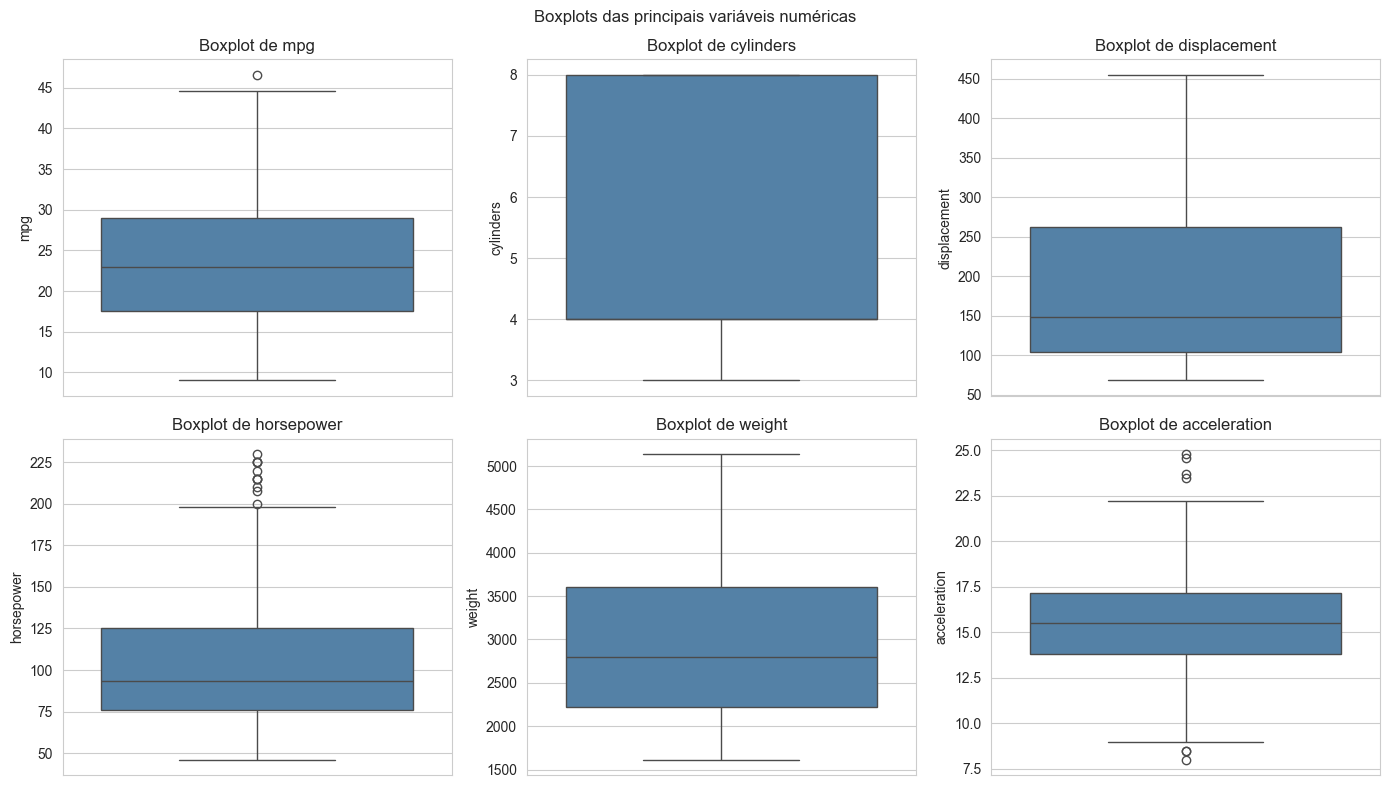

In [12]:
colunas_numericas = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, coluna in enumerate(colunas_numericas):
    sns.boxplot(y=df[coluna], ax=axes[i], color='steelblue')
    axes[i].set_title(f'Boxplot de {coluna}')
    axes[i].set_ylabel(coluna)
fig.suptitle('Boxplots das principais variáveis numéricas')
plt.tight_layout()
plt.show()

In [13]:
def contar_outliers_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    return ((serie < limite_inferior) | (serie > limite_superior)).sum()

for coluna in colunas_numericas:
    print(f'{coluna}: {contar_outliers_iqr(df[coluna])} possíveis outliers')

mpg: 1 possíveis outliers
cylinders: 0 possíveis outliers
displacement: 0 possíveis outliers
horsepower: 11 possíveis outliers
weight: 0 possíveis outliers
acceleration: 7 possíveis outliers


Pelo critério do IQR, `horsepower` (11 registros) e `acceleration` (7 registros) são as variáveis com mais valores nos extremos, e `mpg` tem apenas 1. `cylinders`, `displacement` e `weight` não têm nenhum valor fora do intervalo.

Olhando o contexto, esses valores extremos representam veículos que realmente existiam na época: carros com motores muito potentes (V8 de mais de 200 cavalos, como picapes e carros grandes americanos) e carros muito econômicos e leves (como o Mazda GLC, de 46.6 mpg, que é o próprio valor mais alto da variável `mpg`). Não parece ser erro de digitação nem de medição, só carros nos dois extremos do mercado da época: motores muito grandes de um lado, carros compactos e eficientes do outro.

Por isso optamos por manter todos os outliers no dataset. Removê-los tiraria informação real sobre a variabilidade dos veículos, o que prejudicaria a capacidade dos modelos de aprender o comportamento de toda a faixa de consumo.

### Análise Exploratória de Dados (EDA)

#### Gráfico 1: peso (weight) x MPG

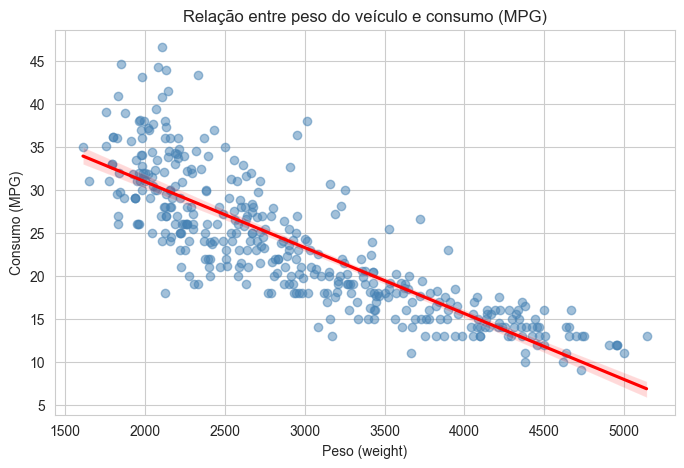

In [14]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='weight', y='mpg', scatter_kws={'alpha': 0.5, 'color': 'steelblue'}, line_kws={'color': 'red'})
plt.title('Relação entre peso do veículo e consumo (MPG)')
plt.xlabel('Peso (weight)')
plt.ylabel('Consumo (MPG)')
plt.show()

In [15]:
print('Correlação weight x mpg:', round(df['weight'].corr(df['mpg']), 3))

Correlação weight x mpg: -0.832


O gráfico mostra claramente uma relação negativa: quanto mais pesado o veículo, menor o seu MPG. A correlação entre as duas variáveis é de aproximadamente **-0.83**, uma das mais fortes do dataset, confirmando que o peso é um forte indicador do consumo.

#### Gráfico 2: potência (horsepower) x MPG

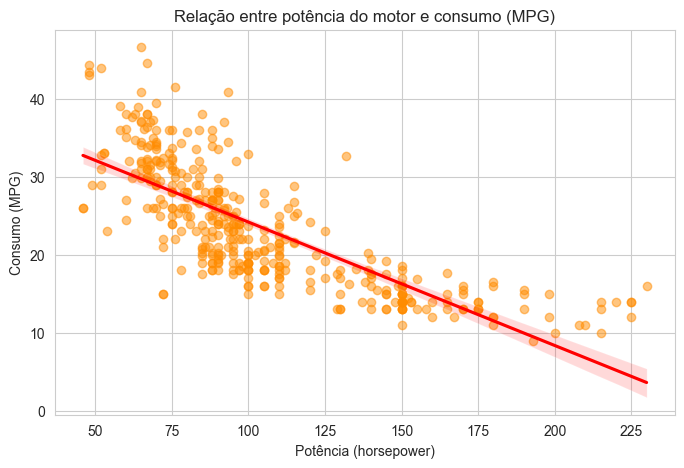

In [16]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='horsepower', y='mpg', scatter_kws={'alpha': 0.5, 'color': 'darkorange'}, line_kws={'color': 'red'})
plt.title('Relação entre potência do motor e consumo (MPG)')
plt.xlabel('Potência (horsepower)')
plt.ylabel('Consumo (MPG)')
plt.show()

In [17]:
print('Correlação horsepower x mpg:', round(df['horsepower'].corr(df['mpg']), 3))

Correlação horsepower x mpg: -0.773


Também existe uma relação negativa entre potência e MPG (correlação de aproximadamente **-0.77**): motores mais potentes tendem a consumir mais combustível, resultando em menor MPG.

#### Gráfico 3: distribuição do MPG

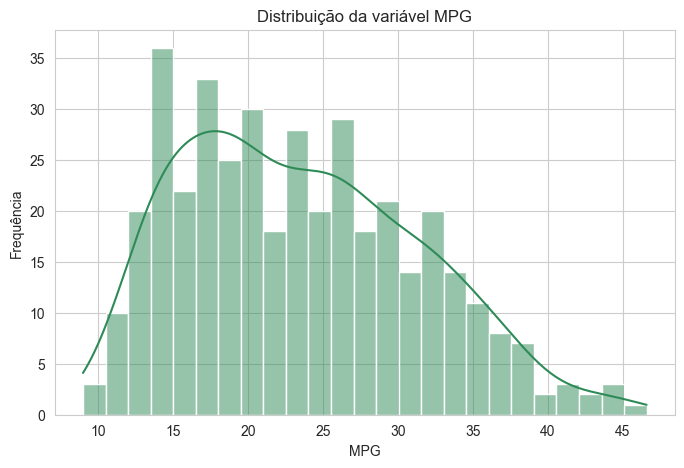

In [18]:
plt.figure(figsize=(8, 5))
sns.histplot(df['mpg'], bins=25, color='seagreen', kde=True)
plt.title('Distribuição da variável MPG')
plt.xlabel('MPG')
plt.ylabel('Frequência')
plt.show()

A distribuição do MPG é levemente assimétrica à direita: a maior parte dos veículos se concentra entre 15 e 30 MPG, com uma cauda mais longa em direção aos valores altos de consumo eficiente (acima de 35 MPG), representados principalmente por carros mais leves e recentes do dataset.

#### Gráfico 4: correlação entre as variáveis numéricas

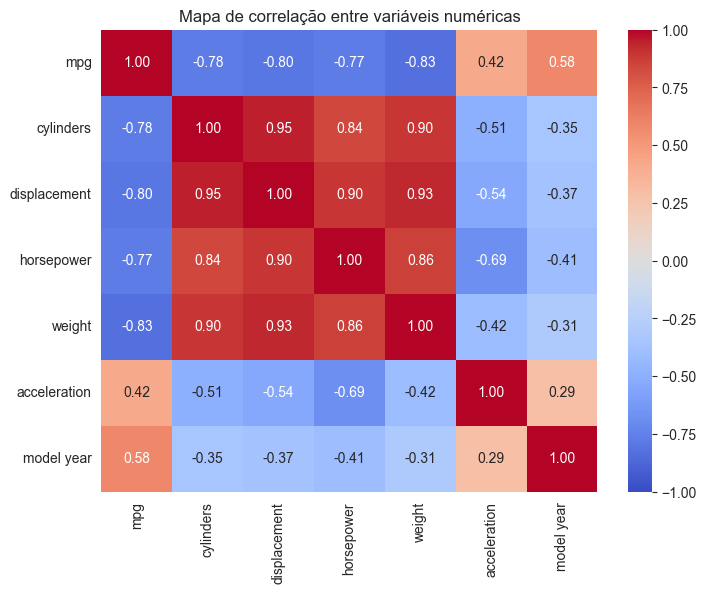

In [19]:
colunas_corr = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year']
matriz_corr = df[colunas_corr].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Mapa de correlação entre variáveis numéricas')
plt.show()

In [20]:
matriz_corr['mpg'].sort_values()

weight         -0.831741
displacement   -0.804203
cylinders      -0.775396
horsepower     -0.773453
acceleration    0.420289
model year      0.579267
mpg             1.000000
Name: mpg, dtype: float64

As variáveis mais fortemente relacionadas ao MPG são `weight` (-0.83), `displacement` (-0.80), `cylinders` (-0.78) e `horsepower` (-0.77): todas com correlação negativa forte, indicando que carros maiores, com motores maiores e mais cilindros, consomem mais. Já `model year` tem correlação positiva (+0.58): carros mais recentes do dataset (fabricados a partir de 1978-1980, período pós-crise do petróleo) tendem a ser mais econômicos. `acceleration` tem correlação positiva mais fraca (+0.42).

### Engenharia de atributos: marca do veículo

A coluna `car name` traz o nome completo do modelo, por exemplo "chevrolet chevelle malibu". A marca é sempre a primeira palavra desse texto, então extraímos essa informação para uma nova coluna `brand`.

In [21]:
df['brand'] = df['car name'].str.split().str[0]
df['brand'].value_counts()

brand
ford             51
chevrolet        43
plymouth         31
amc              28
dodge            28
toyota           25
datsun           23
buick            17
pontiac          16
volkswagen       15
honda            13
mercury          11
oldsmobile       10
mazda            10
peugeot           8
fiat              8
audi              7
chrysler          6
volvo             6
vw                6
renault           5
saab              4
opel              4
subaru            4
chevy             3
bmw               2
maxda             2
mercedes-benz     2
cadillac          2
hi                1
toyouta           1
chevroelt         1
capri             1
mercedes          1
vokswagen         1
triumph           1
nissan            1
Name: count, dtype: int64

Olhando a lista de marcas, dá pra notar nomes que são a mesma marca escrita de forma diferente, provavelmente por erro de digitação ou abreviação:

- `chevrolet`, `chevy` e `chevroelt`: todas são Chevrolet;
- `toyota` e `toyouta`: Toyota, com erro de digitação;
- `mazda` e `maxda`: Mazda, com erro de digitação;
- `volkswagen`, `vw` e `vokswagen`: Volkswagen, com abreviação e erro de digitação;
- `mercedes-benz` e `mercedes`: mesma marca, forma abreviada.

Já `capri` (registro único, "capri ii") e `hi` (registro único, "hi 1200d") não foram alterados. Eles não correspondem a nenhuma variação de grafia de outra marca já presente no dataset, e mudar esses valores exigiria conhecimento externo sobre o fabricante real do veículo, algo que não está evidente só pelo texto da coluna `car name`. Como o enunciado pede pra não inventar correções arbitrárias, preferimos deixar como está.

In [22]:
mapa_marcas = {
    'chevy': 'chevrolet',
    'chevroelt': 'chevrolet',
    'toyouta': 'toyota',
    'maxda': 'mazda',
    'vw': 'volkswagen',
    'vokswagen': 'volkswagen',
    'mercedes': 'mercedes-benz',
}
df['brand'] = df['brand'].replace(mapa_marcas)
contagem_marcas = df['brand'].value_counts()
contagem_marcas

brand
ford             51
chevrolet        47
plymouth         31
amc              28
dodge            28
toyota           26
datsun           23
volkswagen       22
buick            17
pontiac          16
honda            13
mazda            12
mercury          11
oldsmobile       10
peugeot           8
fiat              8
audi              7
chrysler          6
volvo             6
renault           5
saab              4
opel              4
subaru            4
mercedes-benz     3
bmw               2
cadillac          2
hi                1
capri             1
triumph           1
nissan            1
Name: count, dtype: int64

In [23]:
print('Quantidade de marcas distintas após padronização:', df['brand'].nunique())

Quantidade de marcas distintas após padronização: 30


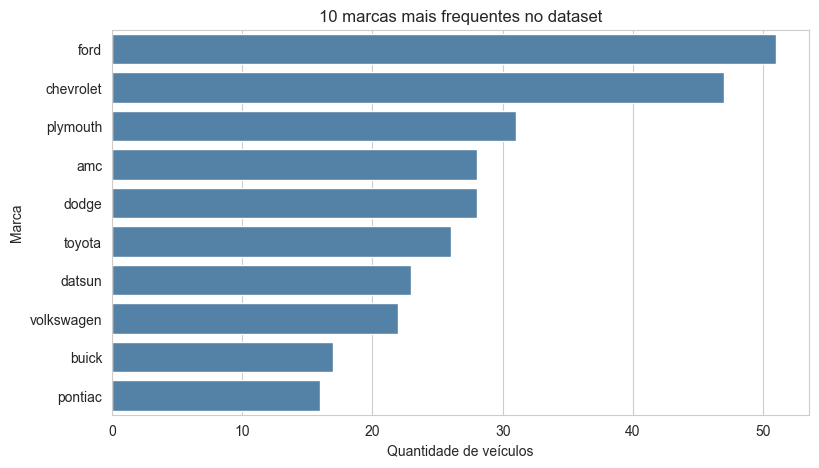

In [24]:
top_marcas = contagem_marcas.head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=top_marcas.values, y=top_marcas.index, color='steelblue')
plt.title('10 marcas mais frequentes no dataset')
plt.xlabel('Quantidade de veículos')
plt.ylabel('Marca')
plt.show()

Depois da padronização, o dataset passou de 37 para 30 marcas distintas. As marcas mais frequentes são `ford` (51), `chevrolet` (47, depois de unir as variações), `plymouth` (31), `amc` e `dodge` (28 cada). Isso mostra o predomínio de fabricantes americanos no período do dataset.

In [25]:
mpg_por_marca = df[df['brand'].isin(top_marcas.index)].groupby('brand')['mpg'].mean().sort_values(ascending=False)
mpg_por_marca

brand
volkswagen    31.840909
datsun        31.113043
toyota        28.165385
dodge         22.060714
plymouth      21.703226
chevrolet     20.219149
pontiac       20.012500
ford          19.694118
buick         19.182353
amc           18.246429
Name: mpg, dtype: float64

Entre as marcas mais frequentes, `volkswagen`, `datsun` e `toyota` (fabricantes europeus/japoneses de carros compactos) têm o MPG médio mais alto, enquanto marcas americanas tradicionais como `amc`, `buick` e `ford` aparecem com MPG médio mais baixo. Isso sugere uma relação entre a marca/região de origem e o consumo, que será confirmada na análise de origem a seguir.

### Região de origem

A coluna `origin` traz um código numérico (1, 2 ou 3) que, segundo a documentação do dataset Auto MPG, representa a região de fabricação do veículo: 1 = Estados Unidos, 2 = Europa e 3 = Japão. Criamos uma coluna com esses nomes para facilitar a leitura.

In [26]:
mapa_origem = {1: 'USA', 2: 'Europe', 3: 'Japan'}
df['origin_name'] = df['origin'].map(mapa_origem)
df.groupby('origin_name')['mpg'].agg(['mean', 'median', 'count'])

,mean,median,count
origin_name,,,
Europe,27.891429,26.5,70
Japan,30.450633,31.6,79
USA,20.083534,18.5,249


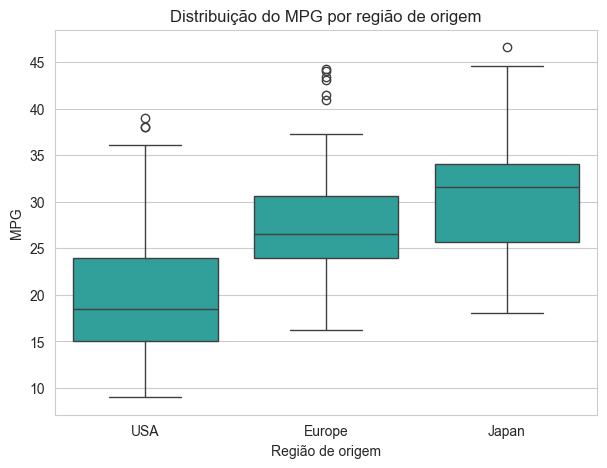

In [27]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='origin_name', y='mpg', order=['USA', 'Europe', 'Japan'], color='lightseagreen')
plt.title('Distribuição do MPG por região de origem')
plt.xlabel('Região de origem')
plt.ylabel('MPG')
plt.show()

Os resultados mostram uma diferença clara entre regiões: veículos americanos têm MPG médio de aproximadamente 20.1, os europeus 27.9, e os japoneses 30.5. Isso é coerente com o que já havia aparecido na análise de marcas: fabricantes japoneses e europeus do dataset produziam, em geral, carros menores e mais econômicos, enquanto os fabricantes americanos, no período analisado, ainda produziam muitos veículos grandes e potentes.

### Escalonamento

Redes neurais como a MLP, que usaremos na Etapa 2, aprendem por meio de gradientes calculados a partir dos valores de entrada. Se as variáveis estiverem em escalas muito diferentes (por exemplo, `weight` na casa dos milhares e `acceleration` na casa das dezenas), a rede pode dar peso desproporcional às variáveis de maior magnitude e demorar mais para convergir. Por isso, aplicamos o `StandardScaler`, que transforma cada variável para média 0 e desvio padrão 1.

Para isso, primeiro definimos as variáveis preditoras (`X`) e o alvo (`y`), e já fazemos aqui a divisão em treino/validação/teste, pois o escalonamento **precisa ser ajustado apenas com os dados de treinamento**, para evitar vazamento de dados (usar informação do teste/validação para calibrar o scaler seria uma forma de "trapaça" que deixaria a avaliação final otimista demais). Esses mesmos conjuntos serão reaproveitados na Etapa 2.

In [28]:
df_modelo = pd.get_dummies(df, columns=['origin_name'], prefix='origin', drop_first=True)

colunas_preditoras = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year'] + \
    [coluna for coluna in df_modelo.columns if coluna.startswith('origin_')]

X = df_modelo[colunas_preditoras].astype(float)
y = df_modelo['mpg'].astype(float)

print('Variáveis preditoras utilizadas:', colunas_preditoras)

Variáveis preditoras utilizadas: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'origin_Japan', 'origin_USA']


Usamos `drop_first=True` na criação das variáveis dummy de origem para remover uma das três categorias (Europe) como referência, evitando redundância entre as colunas (a chamada "armadilha da variável dummy"). Não incluímos a marca (`brand`) diretamente como variável preditora, pois ela tem muitas categorias com poucos exemplos cada, o que tornaria o modelo desnecessariamente complexo para os objetivos deste trabalho.

In [29]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print('Treino:', X_train.shape[0], 'registros')
print('Validação:', X_val.shape[0], 'registros')
print('Teste:', X_test.shape[0], 'registros')

Treino: 278 registros
Validação: 60 registros
Teste: 60 registros


In [30]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print('Média das colunas de treino após escalonamento (deve ficar perto de 0):')
print(np.round(X_train_s.mean(axis=0), 3))

Média das colunas de treino após escalonamento (deve ficar perto de 0):
[ 0. -0. -0.  0. -0.  0.  0.  0.]


O `scaler` foi ajustado (`fit`) só com `X_train`, e depois só aplicado (`transform`) em `X_val` e `X_test`. Assim, nenhuma informação estatística dos conjuntos de validação e teste (as médias e desvios-padrão reais deles) influencia o treinamento. Isso é essencial para uma avaliação honesta do modelo.

### Dataset final da Etapa 1

In [31]:
print('Tamanho final do dataset:', df.shape)
print('Valores nulos totais:', df.isnull().sum().sum())
print('Duplicatas restantes:', df.duplicated().sum())
df.dtypes

Tamanho final do dataset: (398, 11)
Valores nulos totais: 0
Duplicatas restantes: 0


mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model year        int64
origin            int64
car name            str
brand            object
origin_name         str
dtype: object

O dataset final possui 398 registros, sem valores nulos e sem duplicatas. As colunas adicionadas nesta etapa (`brand` e `origin_name`) complementam os atributos originais e foram úteis na análise exploratória. Para a modelagem, utilizaremos as variáveis numéricas originais (`cylinders`, `displacement`, `horsepower`, `weight`, `acceleration`, `model year`) mais as variáveis de origem codificadas (`origin_Japan`, `origin_USA`). Os dados já estão limpos, sem vazamento entre treino/validação/teste, e prontos para a etapa de modelagem.

## Etapa 2: Inteligência Artificial

Nesta etapa usamos os dados tratados para prever `mpg`, uma tarefa de regressão. Vamos construir dois modelos bem diferentes entre si: uma rede neural MLP, que aprende padrões diretamente dos dados, e um sistema de Lógica Fuzzy, que usa regras baseadas em conhecimento sobre o problema.

## Parte A: MLP

### Separação dos dados

Já criamos os conjuntos de treino, validação e teste na Etapa 1 (seção de escalonamento), usando `random_state=42` para a divisão ser sempre a mesma se o notebook for executado de novo.

Usamos três conjuntos porque cada um tem um papel diferente. O treino serve para a rede neural ajustar os pesos internos. A validação serve para comparar hiperparâmetros diferentes (arquitetura, ativação, learning rate) e escolher o melhor modelo, sem tocar no teste. O teste é usado só uma vez, no final, para medir o desempenho real do modelo escolhido em dados que ele nunca viu e que não influenciaram nenhuma decisão de ajuste.

Se usássemos só treino e teste, e escolhêssemos os hiperparâmetros olhando o desempenho no teste, estaríamos "espiando" o teste de forma indireta, e a métrica final não refletiria mais a capacidade real de generalização do modelo.

In [32]:
print('Treino:', X_train_s.shape)
print('Validação:', X_val_s.shape)
print('Teste:', X_test_s.shape)

Treino: (278, 8)
Validação: (60, 8)
Teste: (60, 8)


### Pré-processamento

O escalonamento já foi feito na Etapa 1: `scaler.fit_transform` no treino e `scaler.transform` na validação e no teste. Não é necessário repetir esse passo, apenas reaproveitamos `X_train_s`, `X_val_s` e `X_test_s`.

### Modelo MLP

Criamos um modelo `MLPRegressor` com uma arquitetura inicial razoável: duas camadas ocultas, com 32 e 16 neurônios, ativação `relu` (usual em redes neurais modernas por evitar o problema do gradiente desaparecendo) e `learning_rate_init=0.01`. Definimos `max_iter=2000` para dar tempo suficiente de convergência e `random_state=42` para reprodutibilidade.

In [33]:
mlp_base = MLPRegressor(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    learning_rate_init=0.01,
    max_iter=2000,
    random_state=42,
)
mlp_base.fit(X_train_s, y_train)

print('Arquitetura (neurônios por camada oculta):', mlp_base.hidden_layer_sizes)
print('Função de ativação:', mlp_base.activation)
print('Número de iterações até convergir:', mlp_base.n_iter_)
print('Erro (loss) final de treinamento:', round(mlp_base.loss_, 4))

Arquitetura (neurônios por camada oculta): (32, 16)
Função de ativação: relu
Número de iterações até convergir: 381
Erro (loss) final de treinamento: 2.8079


In [34]:
pred_train_base = mlp_base.predict(X_train_s)
print('R² no conjunto de treino:', round(r2_score(y_train, pred_train_base), 4))

R² no conjunto de treino: 0.9101


O modelo convergiu antes de atingir o limite de 2000 iterações, e apresenta um R² de treino alto, indicando que a rede conseguiu aprender bem os padrões do conjunto de treinamento. O desempenho real (em dados novos) só será conhecido depois da escolha do melhor modelo e da avaliação no conjunto de teste.

### Retropropagação e decaimento do erro

O `MLPRegressor` treina internamente usando o algoritmo de **retropropagação (backpropagation)**: a cada iteração, o erro da previsão é calculado e propagado da saída para as camadas anteriores, ajustando os pesos da rede na direção que reduz esse erro (gradiente descendente). O histórico desses erros fica disponível em `loss_curve_`.

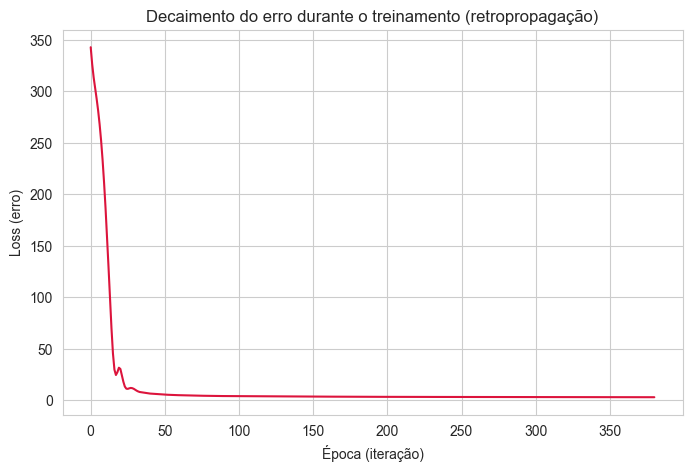

In [35]:
plt.figure(figsize=(8, 5))
plt.plot(mlp_base.loss_curve_, color='crimson')
plt.title('Decaimento do erro durante o treinamento (retropropagação)')
plt.xlabel('Época (iteração)')
plt.ylabel('Loss (erro)')
plt.show()

O gráfico mostra uma queda acentuada do erro nas primeiras iterações, seguida por uma redução mais suave até estabilizar próximo de 2.81 (valor exibido na saída da célula anterior como `loss_ final`). Essa curva decrescente confirma que a retropropagação está de fato ajustando os pesos da rede na direção correta, reduzindo o erro de treinamento a cada época, até que o modelo convirja.

### Experimentos com hiperparâmetros

Vamos testar diferentes combinações de arquitetura, função de ativação e learning rate. Os experimentos são avaliados apenas no conjunto de validação. O conjunto de teste fica intocado até a avaliação final do melhor modelo.

In [36]:
experimentos = [
    ('(16,)',   (16,),    'relu', 0.01),
    ('(32,)',   (32,),    'relu', 0.01),
    ('(64,)',   (64,),    'relu', 0.01),
    ('(32,16)', (32, 16), 'relu', 0.01),
    ('(32,16)', (32, 16), 'tanh', 0.01),
    ('(32,16)', (32, 16), 'relu', 0.001),
    ('(32,16)', (32, 16), 'relu', 0.05),
    ('(64,)',   (64,),    'tanh', 0.001),
]

resultados = []
modelos_treinados = {}

for indice, (nome_arquitetura, arquitetura, ativacao, lr) in enumerate(experimentos):
    modelo = MLPRegressor(
        hidden_layer_sizes=arquitetura,
        activation=ativacao,
        learning_rate_init=lr,
        max_iter=2000,
        random_state=42,
    )
    modelo.fit(X_train_s, y_train)
    pred_val = modelo.predict(X_val_s)

    resultados.append({
        'arquitetura': nome_arquitetura,
        'ativacao': ativacao,
        'learning_rate': lr,
        'rmse_val': mean_squared_error(y_val, pred_val) ** 0.5,
        'mae_val': mean_absolute_error(y_val, pred_val),
        'r2_val': r2_score(y_val, pred_val),
        'n_iter': modelo.n_iter_,
        'indice': indice,
    })
    modelos_treinados[indice] = modelo

df_experimentos = pd.DataFrame(resultados)
df_experimentos

,arquitetura,ativacao,learning_rate,rmse_val,mae_val,r2_val,n_iter,indice
0,"(16,)",relu,0.010,2.486107,1.946191,0.874032,556,0
1,"(32,)",relu,0.010,2.485537,1.914263,0.874090,484,1
2,"(64,)",relu,0.010,2.464890,1.945497,0.876173,485,2
3,"(32,16)",relu,0.010,2.321287,1.816340,0.890181,381,3
4,"(32,16)",tanh,0.010,2.827037,2.163318,0.837115,719,4
5,"(32,16)",relu,0.001,2.387745,1.855276,0.883803,1517,5
6,"(32,16)",relu,0.050,2.229301,1.749188,0.898712,228,6
7,"(64,)",tanh,0.001,2.632575,1.979483,0.858752,1789,7


In [37]:
melhor_linha = df_experimentos.loc[df_experimentos['r2_val'].idxmax()]
melhor_modelo = modelos_treinados[melhor_linha['indice']]
print('Melhor combinação de hiperparâmetros (segundo R² na validação):')
print(melhor_linha)

Melhor combinação de hiperparâmetros (segundo R² na validação):
arquitetura       (32,16)
ativacao             relu
learning_rate        0.05
rmse_val         2.229301
mae_val          1.749188
r2_val           0.898712
n_iter                228
indice                  6
Name: 6, dtype: object


Entre os experimentos testados, a combinação com melhor desempenho na validação foi a arquitetura `(32,16)`, ativação `relu` e `learning_rate_init=0.05`. Aumentar demais o número de neurônios em uma única camada `(64,)` não trouxe ganho equivalente ao de usar duas camadas menores `(32,16)`, e a ativação `tanh` teve desempenho pior que `relu` neste problema. Agora avaliamos esse modelo escolhido no conjunto de teste, que ainda não tinha sido usado em nenhuma decisão.

In [38]:
pred_test = melhor_modelo.predict(X_test_s)

r2_mlp = r2_score(y_test, pred_test)
rmse_mlp = mean_squared_error(y_test, pred_test) ** 0.5
mae_mlp = mean_absolute_error(y_test, pred_test)

print(f'R² no teste: {r2_mlp:.4f}')
print(f'RMSE no teste: {rmse_mlp:.4f}')
print(f'MAE no teste: {mae_mlp:.4f}')

R² no teste: 0.8983
RMSE no teste: 2.5853
MAE no teste: 1.9023


### Métricas da MLP

- **R² (coeficiente de determinação)**: indica quanto da variação do MPG real é explicada pelo modelo. Varia, na prática, de 0 a 1 (pode ficar negativo se o modelo for pior que simplesmente prever a média); quanto mais próximo de 1, melhor.
- **RMSE (raiz do erro quadrático médio)**: mede o erro médio das previsões, na mesma unidade do MPG, penalizando mais os erros grandes.
- **MAE (erro absoluto médio)**: mede, em média, o quanto a previsão se distancia do valor real, sem dar peso extra a erros grandes.

In [39]:
tabela_metricas_mlp = pd.DataFrame({
    'Métrica': ['R²', 'RMSE', 'MAE'],
    'Valor': [round(r2_mlp, 4), round(rmse_mlp, 4), round(mae_mlp, 4)],
})
tabela_metricas_mlp

,Métrica,Valor
0,R²,0.8983
1,RMSE,2.5853
2,MAE,1.9023


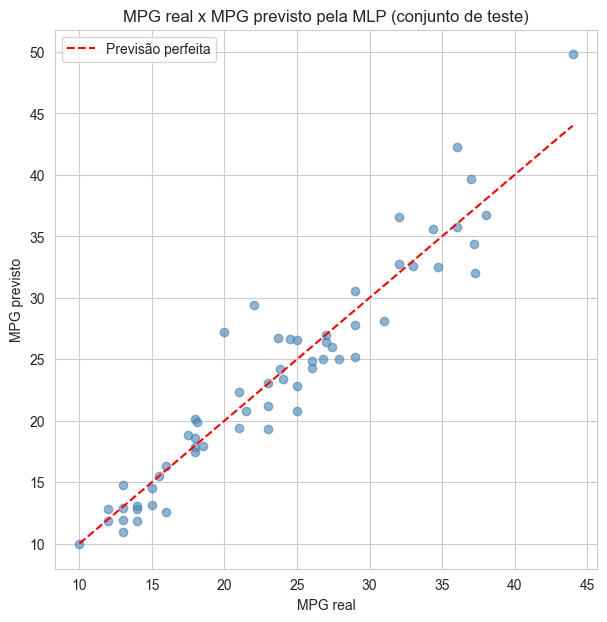

In [40]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, pred_test, alpha=0.6, color='steelblue')
limite_min, limite_max = y_test.min(), y_test.max()
plt.plot([limite_min, limite_max], [limite_min, limite_max], color='red', linestyle='--', label='Previsão perfeita')
plt.title('MPG real x MPG previsto pela MLP (conjunto de teste)')
plt.xlabel('MPG real')
plt.ylabel('MPG previsto')
plt.legend()
plt.show()

Os pontos ficam concentrados próximos da linha diagonal (previsão perfeita), o que é coerente com o R² de aproximadamente 0.898 obtido no teste (ver saída da célula anterior): a MLP explica uma parte substancial da variação do MPG a partir das variáveis técnicas do veículo, com um erro médio (MAE) de aproximadamente 1.90 MPG.

## Parte B: sistema de inferência Fuzzy

### Justificativa das variáveis

Para o sistema Fuzzy, escolhemos `weight` (peso) e `horsepower` (potência) como entradas, e `mpg` como saída. Essa escolha tem uma justificativa física direta:

- veículos mais pesados exigem mais energia do motor para se movimentar, o que tende a aumentar o consumo (reduzir o MPG);
- motores mais potentes geralmente são maiores e mais robustos, e em muitos casos consomem mais combustível para gerar mais força;
- peso e potência juntos já capturam boa parte da lógica física por trás do consumo de um veículo, sendo variáveis fáceis de descrever com regras do tipo "SE... ENTÃO..."

### Variáveis linguísticas

Para não escolher os limites das funções de pertinência de forma arbitrária, olhamos primeiro para as estatísticas reais de `weight`, `horsepower` e `mpg` no dataset (mínimo, quartis, mediana e máximo).

In [41]:
df[['weight', 'horsepower', 'mpg']].describe().loc[['min', '25%', '50%', '75%', 'max']]

,weight,horsepower,mpg
min,1613.00,46.0,9.0
25%,2223.75,76.0,17.5
50%,2803.50,93.5,23.0
75%,3608.00,125.0,29.0
max,5140.00,230.0,46.6


In [42]:
w_min, w_q1, w_med, w_q3, w_max = df['weight'].min(), df['weight'].quantile(.25), df['weight'].median(), df['weight'].quantile(.75), df['weight'].max()
h_min, h_q1, h_med, h_q3, h_max = df['horsepower'].min(), df['horsepower'].quantile(.25), df['horsepower'].median(), df['horsepower'].quantile(.75), df['horsepower'].max()
m_min, m_q1, m_med, m_q3, m_max = df['mpg'].min(), df['mpg'].quantile(.25), df['mpg'].median(), df['mpg'].quantile(.75), df['mpg'].max()

print('weight  ->', w_min, w_q1, w_med, w_q3, w_max)
print('horsepower ->', h_min, h_q1, h_med, h_q3, h_max)
print('mpg ->', m_min, m_q1, m_med, m_q3, m_max)

weight  -> 1613 2223.75 2803.5 3608.0 5140
horsepower -> 46.0 76.0 93.5 125.0 230.0
mpg -> 9.0 17.5 23.0 29.0 46.6


Usamos essas estatísticas para montar as funções de pertinência: o primeiro quartil (25%) e a mediana (50%) marcam a transição entre "leve/baixo" e "médio", e a mediana e o terceiro quartil (75%) marcam a transição entre "médio" e "pesado/alto". Assim, cada categoria linguística cobre aproximadamente um quarto dos veículos do dataset nas extremidades, e a categoria "médio" cobre a faixa central, entre o primeiro e o terceiro quartil.

Usamos funções **trapezoidais** para as categorias das extremidades (`leve`/`pesado`, `baixa`/`alta`, `baixo`/`alto`), pois elas têm um "platô" que representa bem valores muito abaixo do Q1 (ou muito acima do Q3) como totalmente pertencentes àquela categoria. E usamos uma função **triangular** para a categoria central (`médio`), que tem um pico único exatamente na mediana.

In [43]:
peso = ctrl.Antecedent(np.arange(w_min, w_max + 1, 1), 'peso')
potencia = ctrl.Antecedent(np.arange(h_min, h_max + 1, 1), 'potencia')
mpg_fuzzy = ctrl.Consequent(np.arange(m_min, m_max + 0.5, 0.5), 'mpg')

peso['leve'] = fuzz.trapmf(peso.universe, [w_min, w_min, w_q1, w_med])
peso['medio'] = fuzz.trimf(peso.universe, [w_q1, w_med, w_q3])
peso['pesado'] = fuzz.trapmf(peso.universe, [w_med, w_q3, w_max, w_max])

potencia['baixa'] = fuzz.trapmf(potencia.universe, [h_min, h_min, h_q1, h_med])
potencia['media'] = fuzz.trimf(potencia.universe, [h_q1, h_med, h_q3])
potencia['alta'] = fuzz.trapmf(potencia.universe, [h_med, h_q3, h_max, h_max])

mpg_fuzzy['baixo'] = fuzz.trapmf(mpg_fuzzy.universe, [m_min, m_min, m_q1, m_med])
mpg_fuzzy['medio'] = fuzz.trimf(mpg_fuzzy.universe, [m_q1, m_med, m_q3])
mpg_fuzzy['alto'] = fuzz.trapmf(mpg_fuzzy.universe, [m_med, m_q3, m_max, m_max])

### Visualização das funções de pertinência

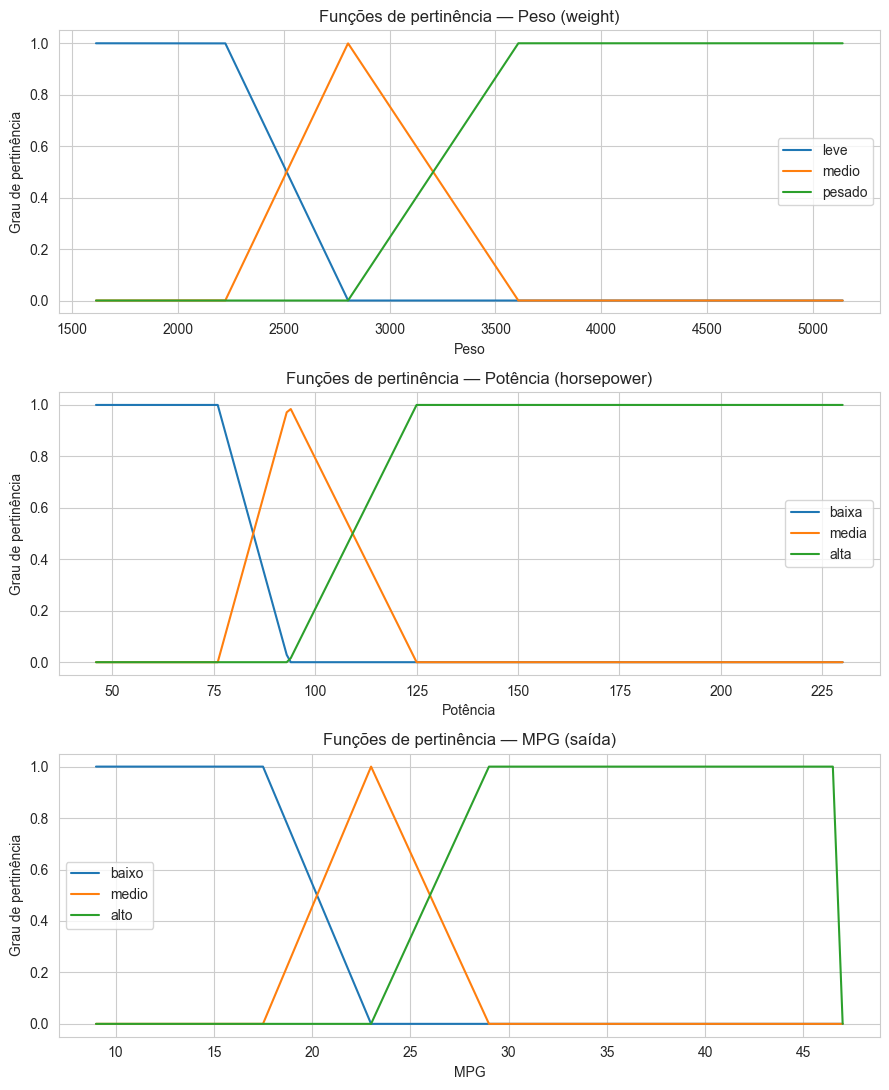

In [44]:
fig, axes = plt.subplots(3, 1, figsize=(9, 11))

for termo in peso.terms:
    axes[0].plot(peso.universe, peso[termo].mf, label=termo)
axes[0].set_title('Funções de pertinência — Peso (weight)')
axes[0].set_xlabel('Peso')
axes[0].set_ylabel('Grau de pertinência')
axes[0].legend()

for termo in potencia.terms:
    axes[1].plot(potencia.universe, potencia[termo].mf, label=termo)
axes[1].set_title('Funções de pertinência — Potência (horsepower)')
axes[1].set_xlabel('Potência')
axes[1].set_ylabel('Grau de pertinência')
axes[1].legend()

for termo in mpg_fuzzy.terms:
    axes[2].plot(mpg_fuzzy.universe, mpg_fuzzy[termo].mf, label=termo)
axes[2].set_title('Funções de pertinência — MPG (saída)')
axes[2].set_xlabel('MPG')
axes[2].set_ylabel('Grau de pertinência')
axes[2].legend()

plt.tight_layout()
plt.show()

Cada gráfico mostra como um valor de entrada (ou saída) pode pertencer, em diferentes graus, a mais de uma categoria ao mesmo tempo. Por exemplo, um veículo com peso próximo à mediana (2803 lb) pertence fortemente à categoria "médio", mas pode também ter um grau de pertinência menor em "leve" ou "pesado", dependendo de quão perto está das transições. Essa é a principal diferença da lógica fuzzy em relação à lógica tradicional, que exigiria uma fronteira rígida (por exemplo, "leve" ou "não leve").

### Base de regras Fuzzy

A base de regras segue a lógica física apresentada na justificativa: peso e potência baixos aumentam o MPG, e peso e potência altos reduzem o MPG. Criamos uma regra para cada uma das 9 combinações possíveis entre as 3 categorias de peso e as 3 categorias de potência, garantindo cobertura completa do espaço de entrada:

| Peso | Potência | MPG |
|---|---|---|
| leve | baixa | alto |
| leve | média | alto |
| leve | alta | médio |
| médio | baixa | alto |
| médio | média | médio |
| médio | alta | baixo |
| pesado | baixa | médio |
| pesado | média | baixo |
| pesado | alta | baixo |

A lógica geral é: quando peso e potência "empurram" o consumo na mesma direção (ambos baixos, ou ambos altos), o resultado é claro (MPG alto ou baixo). Quando um fator compensa o outro (por exemplo, peso leve mas potência alta), o resultado fica em uma categoria intermediária (médio).

In [45]:
regras = [
    ctrl.Rule(peso['leve'] & potencia['baixa'], mpg_fuzzy['alto']),
    ctrl.Rule(peso['leve'] & potencia['media'], mpg_fuzzy['alto']),
    ctrl.Rule(peso['leve'] & potencia['alta'], mpg_fuzzy['medio']),
    ctrl.Rule(peso['medio'] & potencia['baixa'], mpg_fuzzy['alto']),
    ctrl.Rule(peso['medio'] & potencia['media'], mpg_fuzzy['medio']),
    ctrl.Rule(peso['medio'] & potencia['alta'], mpg_fuzzy['baixo']),
    ctrl.Rule(peso['pesado'] & potencia['baixa'], mpg_fuzzy['medio']),
    ctrl.Rule(peso['pesado'] & potencia['media'], mpg_fuzzy['baixo']),
    ctrl.Rule(peso['pesado'] & potencia['alta'], mpg_fuzzy['baixo']),
]

sistema_fuzzy = ctrl.ControlSystem(regras)
print('Total de regras criadas:', len(regras))

Total de regras criadas: 9


### Inferência e defuzzificação

A inferência fuzzy calcula, para um veículo específico, o grau de ativação de cada regra e combina os resultados em um conjunto fuzzy de saída. Como precisamos de um único número de MPG (e não de um conjunto fuzzy), aplicamos a **defuzzificação**: o `scikit-fuzzy` usa por padrão o método do **centroide**, que calcula o "centro de massa" da área resultante da combinação das regras, transformando-a em um valor numérico único.

Vamos executar essa inferência para os mesmos veículos do conjunto de teste usado na avaliação final da MLP, para que a comparação entre os dois modelos seja justa.

In [46]:
df_teste_fuzzy = df.loc[X_test.index]

previsoes_fuzzy = []
for _, linha in df_teste_fuzzy.iterrows():
    simulacao = ctrl.ControlSystemSimulation(sistema_fuzzy)
    simulacao.input['peso'] = float(np.clip(linha['weight'], w_min, w_max))
    simulacao.input['potencia'] = float(np.clip(linha['horsepower'], h_min, h_max))
    simulacao.compute()
    previsoes_fuzzy.append(simulacao.output['mpg'])

previsoes_fuzzy = np.array(previsoes_fuzzy)
y_teste_fuzzy = df_teste_fuzzy['mpg'].values

print('Exemplo de previsões (5 primeiros veículos do teste):')
for real, previsto in list(zip(y_teste_fuzzy, previsoes_fuzzy))[:5]:
    print(f'MPG real: {real:.1f}  |  MPG previsto pelo Fuzzy: {previsto:.2f}')

Exemplo de previsões (5 primeiros veículos do teste):
MPG real: 23.0  |  MPG previsto pelo Fuzzy: 31.72
MPG real: 25.0  |  MPG previsto pelo Fuzzy: 23.06
MPG real: 14.0  |  MPG previsto pelo Fuzzy: 14.74
MPG real: 14.0  |  MPG previsto pelo Fuzzy: 14.74
MPG real: 26.0  |  MPG previsto pelo Fuzzy: 35.70


### Métricas do Fuzzy

In [47]:
r2_fuzzy = r2_score(y_teste_fuzzy, previsoes_fuzzy)
rmse_fuzzy = mean_squared_error(y_teste_fuzzy, previsoes_fuzzy) ** 0.5
mae_fuzzy = mean_absolute_error(y_teste_fuzzy, previsoes_fuzzy)

tabela_metricas_fuzzy = pd.DataFrame({
    'Métrica': ['R²', 'RMSE', 'MAE'],
    'Valor': [round(r2_fuzzy, 4), round(rmse_fuzzy, 4), round(mae_fuzzy, 4)],
})
tabela_metricas_fuzzy

,Métrica,Valor
0,R²,0.4996
1,RMSE,5.7339
2,MAE,4.2716


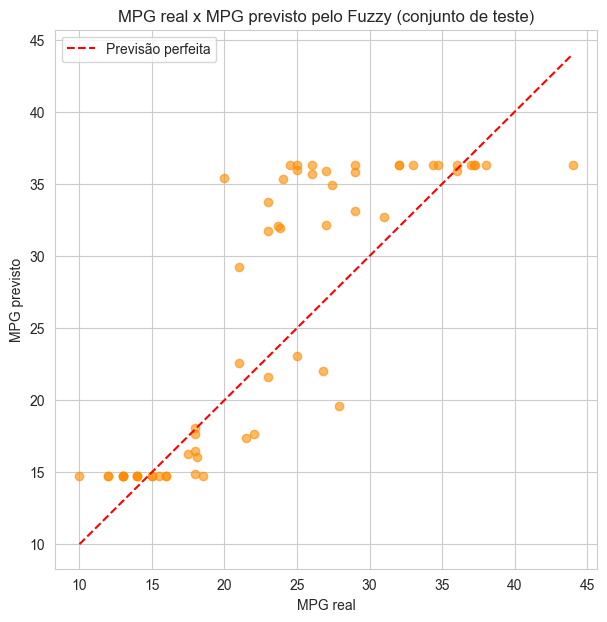

In [48]:
plt.figure(figsize=(7, 7))
plt.scatter(y_teste_fuzzy, previsoes_fuzzy, alpha=0.6, color='darkorange')
limite_min, limite_max = y_teste_fuzzy.min(), y_teste_fuzzy.max()
plt.plot([limite_min, limite_max], [limite_min, limite_max], color='red', linestyle='--', label='Previsão perfeita')
plt.title('MPG real x MPG previsto pelo Fuzzy (conjunto de teste)')
plt.xlabel('MPG real')
plt.ylabel('MPG previsto')
plt.legend()
plt.show()

O sistema Fuzzy obteve R² de aproximadamente 0.500, RMSE de aproximadamente 5.734 e MAE de aproximadamente 4.272 no mesmo conjunto de teste (ver saída da célula anterior). No gráfico, os pontos ficam mais dispersos em torno da linha de previsão perfeita do que no gráfico da MLP, e nota-se uma tendência de "achatamento": como o sistema Fuzzy usa apenas 3 categorias de saída (baixo, médio, alto) combinadas por poucas regras, ele tem menos capacidade de diferenciar valores muito próximos, o que é esperado dado que é um modelo mais simples e baseado em poucas regras.

## Parte C: comparação MLP x Fuzzy

### Tabela comparativa

In [49]:
tabela_comparativa = pd.DataFrame({
    'Modelo': ['MLP', 'Fuzzy'],
    'R²': [round(r2_mlp, 4), round(r2_fuzzy, 4)],
    'RMSE': [round(rmse_mlp, 4), round(rmse_fuzzy, 4)],
    'MAE': [round(mae_mlp, 4), round(mae_fuzzy, 4)],
})
tabela_comparativa

,Modelo,R²,RMSE,MAE
0,MLP,0.8983,2.5853,1.9023
1,Fuzzy,0.4996,5.7339,4.2716


### Comparação dos resultados

Com base na tabela acima (valores obtidos no mesmo conjunto de teste, para uma comparação justa):

1. A MLP teve o R² maior.
2. A MLP teve o RMSE menor.
3. A MLP teve o MAE menor.
4. Considerando as três métricas, a MLP teve melhor precisão neste dataset.
5. O sistema Fuzzy é o modelo mais interpretável, porque as decisões dele vêm de regras explícitas do tipo "SE peso é leve E potência é baixa ENTÃO MPG é alto", que dá pra ler e verificar.
6. A MLP é o modelo "caixa-preta", porque a previsão dela vem de uma combinação de pesos numéricos distribuídos em várias camadas, sem uma regra explícita que explique isoladamente por que aquele valor foi previsto.
7. As regras Fuzzy ajudam na explicabilidade porque cada uma descreve, em linguagem próxima da humana, uma relação física conhecida (peso e potência afetando o consumo). Dá pra justificar uma previsão específica apontando quais regras foram ativadas e com que intensidade.
8. A principal vantagem da MLP é aprender os padrões diretamente dos dados, incluindo relações mais sutis entre todas as variáveis disponíveis, não só peso e potência. Isso geralmente resulta em maior precisão, como se viu neste projeto.
9. A principal vantagem do Fuzzy é não depender de uma grande quantidade de dados de treinamento nem de otimização numérica: ele funciona a partir de conhecimento humano sobre o problema, o que o deixa transparente e fácil de ajustar manualmente.
10. Se a prioridade fosse precisão, a MLP seria a escolhida neste dataset, já que obteve métricas melhores no teste.
11. Se a prioridade fosse transparência ou interpretabilidade, o sistema Fuzzy seria o escolhido, mesmo com precisão menor, porque permite explicar cada decisão em termos compreensíveis.

Esse resultado é específico deste dataset e desta escolha de variáveis: a MLP teve acesso a mais informações (todas as variáveis técnicas e a origem do veículo), enquanto o Fuzzy foi construído de forma deliberadamente simples, usando só peso e potência. Isso não quer dizer que a lógica Fuzzy seja um modelo pior de forma geral, só que, para maximizar a precisão numérica neste problema específico, a MLP teve uma vantagem estrutural de usar mais variáveis e mais parâmetros ajustáveis.

# Conclusão Final

Neste projeto foi possível trabalhar as principais etapas de Ciência de Dados e Inteligência Artificial usando o dataset Auto MPG.

Na etapa de Ciência de Dados, o primeiro aprendizado foi que dados reais quase sempre chegam com problemas. A coluna `horsepower` tinha o caractere `"?"` em 6 registros, o que exigiu conversão explícita para tipo numérico e uma escolha cuidadosa da estratégia de imputação. A mediana se mostrou mais adequada que a média justamente porque a distribuição de potência tem valores extremos (motores muito potentes), que distorceriam a média para cima. Na análise exploratória, apareceu uma relação física esperada: peso e potência têm forte correlação negativa com o MPG (aproximadamente -0.83 e -0.77), enquanto o ano do modelo tem correlação positiva (+0.58), o que acompanha a evolução dos veículos rumo a mais eficiência ao longo da década. A engenharia da variável `brand` mostrou como pequenos erros de grafia (`chevroelt`, `toyouta`, `maxda`, `vw`) podem inflar artificialmente a quantidade de categorias de uma variável, e corrigir isso foi importante para a análise por marca ficar mais próxima da realidade. O escalonamento com `StandardScaler`, ajustado somente no treino, foi essencial para preparar os dados para a MLP sem cometer vazamento de dados.

Na etapa de Inteligência Artificial, a MLP aprendeu a prever o MPG por meio de retropropagação, ajustando os pesos internos a cada iteração para reduzir o erro. Isso pôde ser observado diretamente no gráfico de decaimento da função de perda (`loss_curve_`). O estudo de hiperparâmetros mostrou que a escolha de arquitetura, ativação e learning rate muda o desempenho: a combinação `(32,16)` neurônios, ativação `relu` e `learning_rate_init=0.05` teve o melhor resultado na validação entre as opções testadas, e foi essa combinação, nunca o conjunto de teste, que orientou a escolha do modelo final. O sistema Fuzzy funciona de forma diferente da MLP. Ele não aprende diretamente com os dados: foi construído a partir de estatísticas descritivas (quartis) para calibrar funções de pertinência coerentes com a distribuição real de peso, potência e MPG, e de regras linguísticas que traduzem o conhecimento físico do problema.

Comparando os dois modelos no mesmo conjunto de teste, a MLP teve métricas melhores em todos os critérios (R², RMSE e MAE), o que é esperado já que ela teve acesso a mais variáveis e uma capacidade de ajuste bem maior. Ainda assim, o sistema Fuzzy tem uma vantagem que nenhuma métrica mostra: cada previsão pode ser explicada por regras legíveis, diferente da MLP, cujas decisões estão distribuídas em pesos numéricos difíceis de interpretar individualmente, e por isso ela costuma ser chamada de "caixa-preta". A escolha entre os dois, na prática, depende do que se valoriza mais: precisão numérica (MLP) ou transparência e facilidade de explicação (Fuzzy). Neste projeto, com os dados do Auto MPG, a MLP foi o modelo mais preciso, mas o sistema Fuzzy continua sendo uma alternativa útil quando a interpretabilidade é prioridade.